# Mansi Devganiya
# Track: Data Analytics
# Task: Level 1 - Customer Segmentation Analysis

**Oasis Infobyte | SIP**

## Objective
To segment customers into distinct groups based on their purchasing behaviour using K-Means clustering and RFM analysis (Recency, Frequency, Monetary), and to recommend a marketing action for each segment.

**Dataset:** Customer Personality Analysis (Kaggle), 2,240 customers
**Tools:** Python, pandas, scikit-learn, matplotlib, seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

## 1. Data Loading and Inspection
The file is tab-separated, so it is loaded with sep="\t".

In [7]:
df = pd.read_csv("online retail.csv", sep="\t")   # values in this file are separated by tabs
raw = df.copy()

print("Shape:", df.shape)
df.head()

Shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


## 2. Data Quality Check
Looking for missing values, duplicates and inconsistent or impossible values before any analysis.

In [8]:
print("Data types:\n", df.dtypes.astype(str).to_dict())
print("\nMissing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nDuplicate rows (ignoring ID):", df.drop(columns="ID").duplicated().sum())
print("\nMarital_Status values:", df["Marital_Status"].value_counts().to_dict())
print("\nYear_Birth, Income and Recency summary:")
display(df[["Year_Birth", "Income", "Recency"]].describe().round(1))

Data types:
 {'ID': 'int64', 'Year_Birth': 'int64', 'Education': 'str', 'Marital_Status': 'str', 'Income': 'float64', 'Kidhome': 'int64', 'Teenhome': 'int64', 'Dt_Customer': 'str', 'Recency': 'int64', 'MntWines': 'int64', 'MntFruits': 'int64', 'MntMeatProducts': 'int64', 'MntFishProducts': 'int64', 'MntSweetProducts': 'int64', 'MntGoldProds': 'int64', 'NumDealsPurchases': 'int64', 'NumWebPurchases': 'int64', 'NumCatalogPurchases': 'int64', 'NumStorePurchases': 'int64', 'NumWebVisitsMonth': 'int64', 'AcceptedCmp3': 'int64', 'AcceptedCmp4': 'int64', 'AcceptedCmp5': 'int64', 'AcceptedCmp1': 'int64', 'AcceptedCmp2': 'int64', 'Complain': 'int64', 'Z_CostContact': 'int64', 'Z_Revenue': 'int64', 'Response': 'int64'}

Missing values:
 Income    24
dtype: int64

Duplicate rows (ignoring ID): 182

Marital_Status values: {'Married': 864, 'Together': 580, 'Single': 480, 'Divorced': 232, 'Widow': 77, 'Alone': 3, 'Absurd': 2, 'YOLO': 2}

Year_Birth, Income and Recency summary:


,Year_Birth,Income,Recency
count,2240.0,2216.0,2240.0
mean,1968.8,52247.3,49.1
std,12.0,25173.1,29.0
min,1893.0,1730.0,0.0
25%,1959.0,35303.0,24.0
50%,1970.0,51381.5,49.0
75%,1977.0,68522.0,74.0
max,1996.0,666666.0,99.0


**Observations (problems found):**
- The dataset has 2,240 customers and 29 columns.
- **Missing values:** only Income has missing values (24).
- **Duplicates:** 182 rows are identical in every column except ID. Matching in all 27 other fields by chance is very unlikely, so these are most likely the same customer registered twice.
- **Inconsistent categories:** Marital_Status contains "Alone" (3), "Absurd" (2) and "YOLO" (2), which are not valid statuses.
- **Impossible values:** three customers were born in 1893, 1899 and 1900. The maximum Income is 666,666, more than four times the next highest value (162,397).
- **Other issues:** Dt_Customer is stored as text, and Z_CostContact and Z_Revenue are constant columns (3 and 11) that carry no information.

## 3. Data Cleaning
- **Dates:** Dt_Customer converted to datetime (day-first format).
- **Marital_Status:** "Alone" merged into "Single"; "Absurd" and "YOLO" grouped as "Other".
- **Constant columns:** Z_CostContact and Z_Revenue dropped.
- **Duplicates:** 183 duplicate customers removed (182 found earlier, plus 1 more that became identical after "Alone" was merged into "Single").
- **Impossible values:** 4 rows removed (3 impossible birth years and 1 extreme income of 666,666).
- **Missing Income:** the 24 missing values are filled with the median. Income is not used for clustering, so this choice does not affect the segments.
- **Result:** 2,053 customers remain.

In [9]:
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], dayfirst=True)

df["Marital_Status"] = df["Marital_Status"].replace({"Alone": "Single", "Absurd": "Other", "YOLO": "Other"})

before = len(df)
df = df.drop(columns=["Z_CostContact", "Z_Revenue"])     # constant columns, no information
df = df.drop_duplicates(subset=[c for c in df.columns if c != "ID"])
print("Duplicate customers removed:", before - len(df))

n = len(df)
df = df[(df["Year_Birth"] >= 1920) & ((df["Income"] < 600000) | df["Income"].isnull())]
print("Rows removed for impossible birth year / extreme income:", n - len(df))

print("Missing Income filled with the median:", df["Income"].isnull().sum())
df["Income"] = df["Income"].fillna(df["Income"].median())

print("Rows remaining:", len(df))

Duplicate customers removed: 183
Rows removed for impossible birth year / extreme income: 4
Missing Income filled with the median: 24
Rows remaining: 2053


## 4. Building the RFM Features
- **Recency:** days since the customer's last purchase (already in the data).
- **Frequency:** total purchases across the web, catalogue and store channels.
- **Monetary:** total spend across the six product categories over the last 2 years.
- **Average purchase value:** Monetary divided by Frequency.
- **Customer lifetime value (proxy):** the data covers a 2-year window and has no future information, so the total 2-year spend is used as a simple proxy for lifetime value.

6 customers have zero recorded purchases, so their average purchase value cannot be calculated. They are removed, leaving 2,047 customers.

**Limitation:** each customer has only one row, so Frequency and Monetary come from summary columns and not from individual invoices.

In [10]:
spend_cols = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts",
              "MntSweetProducts", "MntGoldProds"]
purchase_cols = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]

df["Recency_days"] = df["Recency"]
df["Frequency"] = df[purchase_cols].sum(axis=1)     # total purchases (web + catalogue + store)
df["Monetary"] = df[spend_cols].sum(axis=1)          # total spend over the last 2 years

no_purchase = (df["Frequency"] == 0).sum()
df = df[df["Frequency"] > 0].copy()
print("Customers with zero recorded purchases removed:", no_purchase)

df["Avg_Purchase_Value"] = df["Monetary"] / df["Frequency"]
df["CLV_proxy"] = df["Monetary"]
print("Customers analysed:", len(df))

Customers with zero recorded purchases removed: 6
Customers analysed: 2047


## 5. Descriptive Statistics
Average purchase value, purchase frequency and customer lifetime value.

In [11]:
summary = pd.DataFrame({
    "Mean": df[["Recency_days", "Frequency", "Monetary", "Avg_Purchase_Value"]].mean(),
    "Median": df[["Recency_days", "Frequency", "Monetary", "Avg_Purchase_Value"]].median(),
    "Std Dev": df[["Recency_days", "Frequency", "Monetary", "Avg_Purchase_Value"]].std()
}).round(2)
display(summary)

print("Average purchase value :", round(df["Avg_Purchase_Value"].mean(), 2))
print("Average purchase frequency:", round(df["Frequency"].mean(), 2), "purchases")
print("Average customer lifetime value (2-year spend):", round(df["CLV_proxy"].mean(), 2))

,Mean,Median,Std Dev
Recency_days,48.96,49.00,29.00
Frequency,12.58,12.00,7.17
Monetary,608.46,400.00,602.47
Avg_Purchase_Value,38.40,29.92,47.22


Average purchase value : 38.4
Average purchase frequency: 12.58 purchases
Average customer lifetime value (2-year spend): 608.46


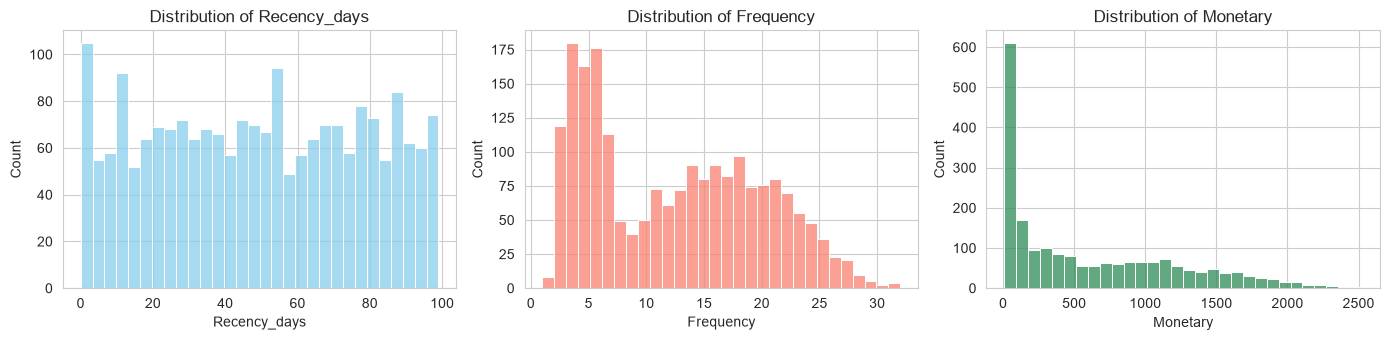

              Recency_days  Frequency  Monetary
Recency_days          1.00       0.00      0.01
Frequency             0.00       1.00      0.82
Monetary              0.01       0.82      1.00


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for a, col, color in zip(ax, ["Recency_days", "Frequency", "Monetary"], ["skyblue", "salmon", "seagreen"]):
    sns.histplot(df[col], bins=30, ax=a, color=color)
    a.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

print(df[["Recency_days", "Frequency", "Monetary"]].corr().round(2))

**Observations:**
- The average customer makes 12.58 purchases, spends 608.46 over 2 years (the lifetime value proxy) and spends 38.40 per purchase on average.
- Spending is right skewed: the mean spend (608.46) is much higher than the median (400.00), and the average purchase value shows the same pattern (38.40 vs 29.92). A group of high spenders pulls the averages up.
- Frequency and Monetary are strongly correlated (0.82), so customers who buy often also spend more.
- Recency is almost uncorrelated with Frequency (0.00) and Monetary (0.01), so it adds independent information, which is why RFM works well here.

## 6. Feature Selection and Scaling
The three RFM features are used for clustering. K-Means is based on distance, so features with large values (Monetary goes up to 2,525, Recency only up to 99) would dominate. StandardScaler brings every feature to mean 0 and standard deviation 1.

In [13]:
features = ["Recency_days", "Frequency", "Monetary"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(df[features])

print("Mean after scaling:", X_scaled.mean(axis=0).round(2))
print("Std after scaling :", X_scaled.std(axis=0).round(2))

Mean after scaling: [-0. -0.  0.]
Std after scaling : [1. 1. 1.]


## 7. Choosing the Number of Clusters (Elbow Method)
K-Means is run for K = 2 to 10. The elbow plot shows how much the inertia falls as K grows, and the silhouette score shows how well separated the clusters are.

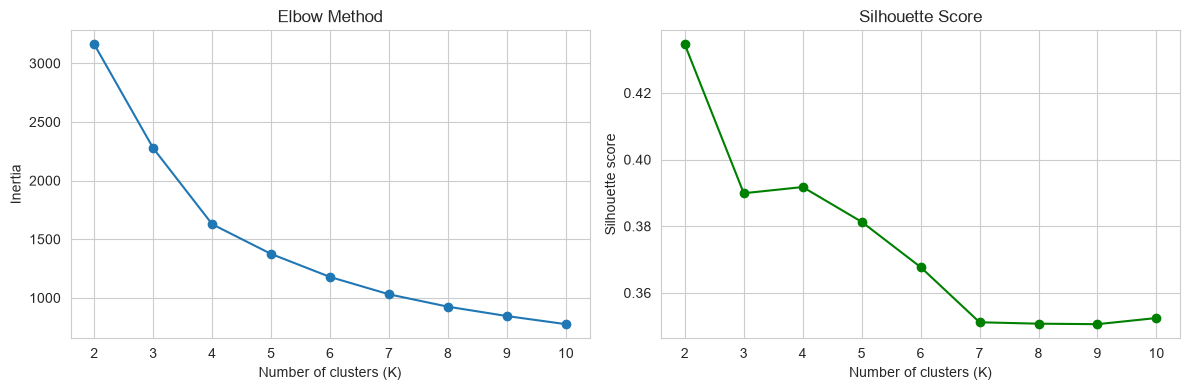

{2: 0.435, 3: 0.39, 4: 0.392, 5: 0.381, 6: 0.368, 7: 0.351, 8: 0.351, 9: 0.351, 10: 0.352}


In [14]:
inertia, silhouette = [], []
k_range = range(2, 11)

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_scaled, labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(list(k_range), inertia, marker="o")
ax[0].set_title("Elbow Method")
ax[0].set_xlabel("Number of clusters (K)")
ax[0].set_ylabel("Inertia")

ax[1].plot(list(k_range), silhouette, marker="o", color="green")
ax[1].set_title("Silhouette Score")
ax[1].set_xlabel("Number of clusters (K)")
ax[1].set_ylabel("Silhouette score")
plt.tight_layout()
plt.show()

print({k: round(s, 3) for k, s in zip(k_range, silhouette)})

**Decision: K = 4**
- The inertia falls sharply up to K = 4 (drops of 885, 648 and 253), and then flattens (196, 148, ...). The elbow is at K = 4.
- The silhouette score is highest at K = 2 (0.435), but two groups are too broad to be useful for marketing. K = 3 (0.390) and K = 4 (0.392) are almost equal.
- K = 4 is chosen because it matches the elbow and gives more specific, actionable segments. A silhouette score of about 0.39 means moderate separation: the segments are meaningful, but there is overlap at the borders.

In [15]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
df["Cluster_raw"] = kmeans.fit_predict(X_scaled)

# Give the clusters a fixed, readable order: high spenders first (most recent buyers first),
# then low spenders (most recent buyers first)
stats = df.groupby("Cluster_raw").agg(avg_spend=("Monetary", "mean"), avg_recency=("Recency_days", "mean"))
stats["high_spender"] = (stats["avg_spend"] > df["Monetary"].mean()).astype(int)
order = stats.sort_values(["high_spender", "avg_recency"], ascending=[False, True]).index
mapping = {old: new for new, old in enumerate(order)}
df["Cluster"] = df["Cluster_raw"].map(mapping)

print("Silhouette score for K =", K, ":", round(silhouette_score(X_scaled, df["Cluster"]), 3))
print(df["Cluster"].value_counts().sort_index())

Silhouette score for K = 4 : 0.392
Cluster
0    431
1    478
2    566
3    572
Name: count, dtype: int64


## 8. Visualising the Clusters
Scatter plots of two feature combinations, and the number of customers in each cluster.

Variance explained by the 2 components: [0.606 0.333] | total: 0.939


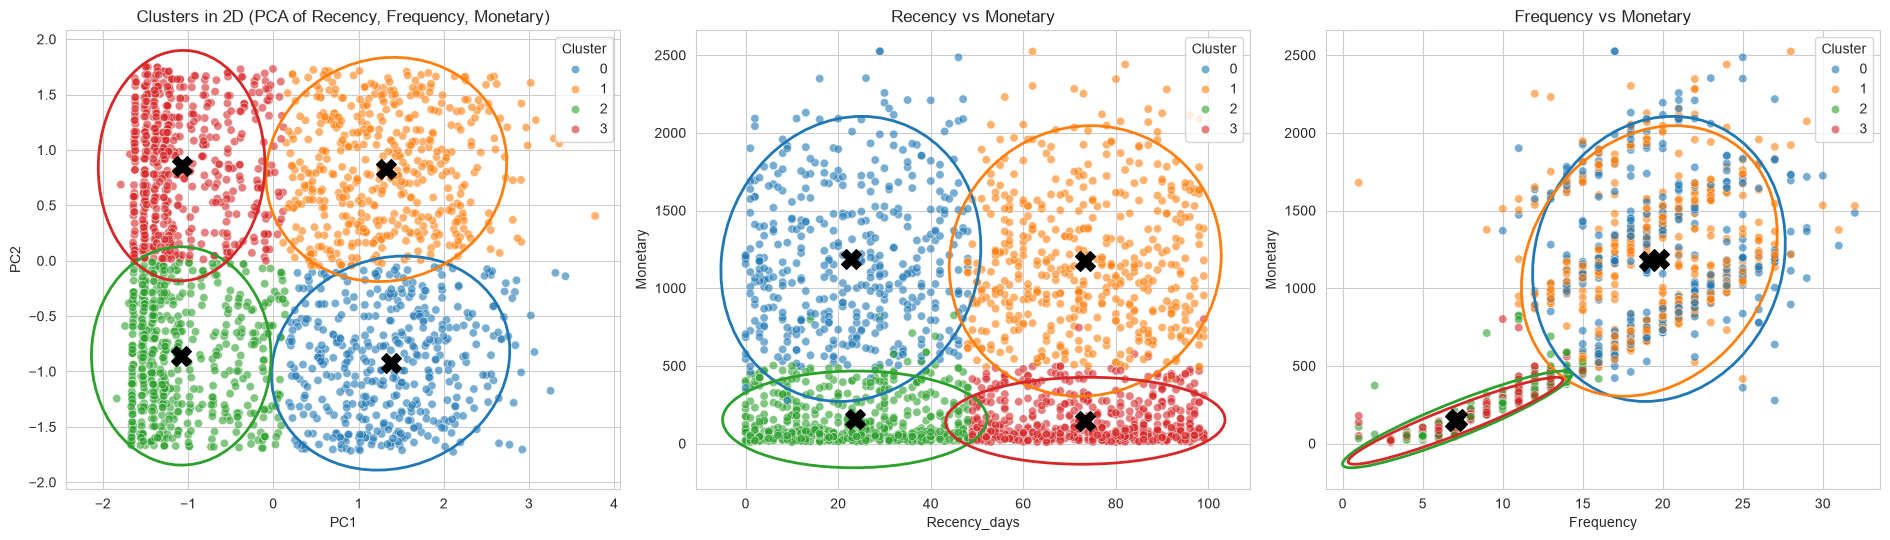

In [21]:
from sklearn.decomposition import PCA
from matplotlib.patches import Ellipse

# Reduce the 3 scaled features to 2 components so all of them can be shown in one plot
pca = PCA(n_components=2, random_state=42)
components = pca.fit_transform(X_scaled)
df["PC1"], df["PC2"] = components[:, 0], components[:, 1]
print("Variance explained by the 2 components:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))

palette = sns.color_palette("tab10", K)

def draw_clusters(ax, x, y):
    sns.scatterplot(data=df, x=x, y=y, hue="Cluster", palette=palette, ax=ax, alpha=0.6)
    for c in range(K):
        d = df[df["Cluster"] == c]
        # ellipse around each cluster (about 2 standard deviations)
        eigvals, eigvecs = np.linalg.eigh(np.cov(d[x], d[y]))
        angle = np.degrees(np.arctan2(*eigvecs[:, 1][::-1]))
        ax.add_patch(Ellipse((d[x].mean(), d[y].mean()),
                             4 * np.sqrt(eigvals[1]), 4 * np.sqrt(eigvals[0]),
                             angle=angle, fill=False, edgecolor=palette[c], linewidth=2))
        # centroid
        ax.scatter(d[x].mean(), d[y].mean(), c="black", s=200, marker="X", zorder=5)

fig, ax = plt.subplots(1, 3, figsize=(19, 5.5))
draw_clusters(ax[0], "PC1", "PC2")
ax[0].set_title("Clusters in 2D (PCA of Recency, Frequency, Monetary)")
draw_clusters(ax[1], "Recency_days", "Monetary")
ax[1].set_title("Recency vs Monetary")
draw_clusters(ax[2], "Frequency", "Monetary")
ax[2].set_title("Frequency vs Monetary")
plt.tight_layout()
plt.show()

C:\Users\Dell\AppData\Local\Temp\ipykernel_22856\3948973519.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=counts.index, y=counts.values, palette="tab10")


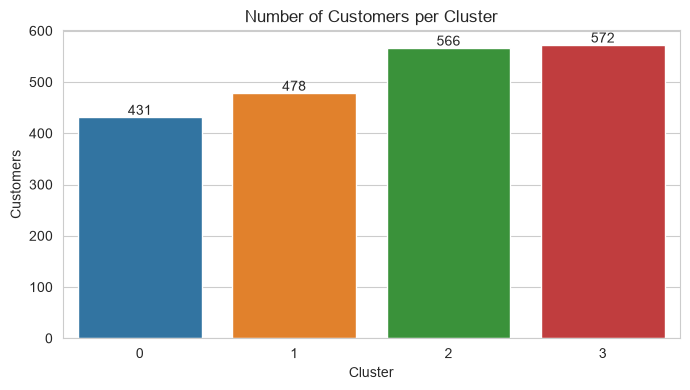

In [18]:
plt.figure(figsize=(7, 4))
counts = df["Cluster"].value_counts().sort_index()
sns.barplot(x=counts.index, y=counts.values, palette="tab10")
for i, v in enumerate(counts.values):
    plt.text(i, v + 5, str(v), ha="center")
plt.title("Number of Customers per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Customers")
plt.tight_layout()
plt.show()

**Observations:**
- The PCA plot combines Recency, Frequency and Monetary into 2 components, which together keep 93.9% of the information (60.6% + 33.3%). In this view the 4 clusters appear as four clearly separated groups around their centroids (black X marks).
- In the Recency vs Monetary plot the clusters split in two ways: by spending level (high versus low) and by recency, with a cut-off at about 48 days since the last purchase.
- In the Frequency vs Monetary plot, clusters 0 and 1 (and also 2 and 3) overlap, because within each pair the customers buy equally often and spend the same amount. They differ only in recency, which this plot does not show.
- The clusters are not perfectly round because Recency is spread evenly between 0 and 99 days and Frequency and Monetary are strongly related (0.82). This is a property of the data, not an error.
- The four clusters are of similar size: 431, 478, 566 and 572 customers.

## 9. Cluster Profiles
Average RFM values, income, website visits and response to the last campaign for each cluster, plus each cluster's share of customers and of total spend.

In [19]:
profile = df.groupby("Cluster").agg(
    Customers=("ID", "count"),
    Avg_Recency_days=("Recency_days", "mean"),
    Avg_Frequency=("Frequency", "mean"),
    Avg_Monetary=("Monetary", "mean"),
    Avg_Purchase_Value=("Avg_Purchase_Value", "mean"),
    Avg_Income=("Income", "mean"),
    Web_Visits_per_Month=("NumWebVisitsMonth", "mean"),
    Last_Campaign_Response_pct=("Response", lambda x: x.mean() * 100)
).round(1)
profile["Share_%"] = (profile["Customers"] / profile["Customers"].sum() * 100).round(1)
profile["Share_of_total_spend_%"] = (df.groupby("Cluster")["Monetary"].sum() / df["Monetary"].sum() * 100).round(1)
profile

,Customers,Avg_Recency_days,Avg_Frequency,Avg_Monetary,Avg_Purchase_Value,Avg_Income,Web_Visits_per_Month,Last_Campaign_Response_pct,Share_%,Share_of_total_spend_%
Cluster,,,,,,,,,,
0,431,22.7,19.8,1188.3,62.3,70381.3,4.1,29.2,21.1,41.1
1,478,73.4,19.2,1175.2,66.4,69024.5,4.0,15.3,23.4,45.1
2,566,23.6,7.1,155.2,17.8,38088.6,6.3,15.7,27.7,7.1
3,572,73.4,7.0,146.4,17.4,37832.3,6.3,4.4,27.9,6.7


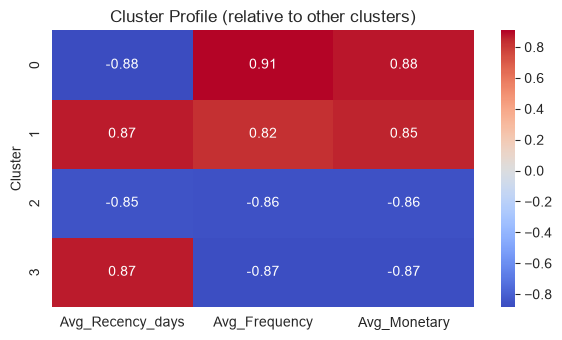

In [20]:
rfm_cols = ["Avg_Recency_days", "Avg_Frequency", "Avg_Monetary"]
profile_scaled = (profile[rfm_cols] - profile[rfm_cols].mean()) / profile[rfm_cols].std()

plt.figure(figsize=(6, 3.5))
sns.heatmap(profile_scaled, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Cluster Profile (relative to other clusters)")
plt.tight_layout()
plt.show()

**Cluster descriptions:**

| Cluster | Segment | Customers | Recency | Frequency | Spend (2 yrs) | Share of spend |
|---|---|---|---|---|---|---|
| 0 | **Loyal High Spenders** | 431 (21.1%) | 22.7 days | 19.8 | 1,188 | 41.1% |
| 1 | **At-Risk High Spenders** | 478 (23.4%) | 73.4 days | 19.2 | 1,175 | 45.1% |
| 2 | **Recent Low Spenders** | 566 (27.7%) | 23.6 days | 7.1 | 155 | 7.1% |
| 3 | **Inactive Low Spenders** | 572 (27.9%) | 73.4 days | 7.0 | 146 | 6.7% |

**Observations:**
- Clusters 0 and 1 together are only 44.5% of customers but bring in 86.2% of total spend.
- Clusters 0 and 1 spend almost the same (about 1,180) and buy equally often, but cluster 1 last bought about 73 days ago against 23 days for cluster 0. The difference between them is recency.
- High spenders have a higher income (about 70,000 vs 38,000) and a larger average purchase (62-66 vs 17-18).
- Cluster 0 responded best to the last campaign (29.2%), followed by clusters 2 (15.7%) and 1 (15.3%). Cluster 3 responded least (4.4%).
- Low spenders visit the website more (6.3 visits per month) than high spenders (about 4), yet spend far less.

## 10. Insights and Marketing Recommendations

**Cluster 0 - Loyal High Spenders (21.1% of customers, 41.1% of spend):** retain and reward. Offer a loyalty programme, early access to new products and premium cross-selling. They already respond best to campaigns (29.2%).

**Cluster 1 - At-Risk High Spenders (23.4% of customers, 45.1% of spend):** the top priority. They are as valuable as cluster 0 but have been inactive for about 73 days, and they respond less (15.3%). Run win-back campaigns with personalised offers and reminders before they leave.

**Cluster 2 - Recent Low Spenders (27.7% of customers, 7.1% of spend):** grow their value. They are recently active and visit the website often (6.3 times per month), but their average purchase is only 17.8. Use bundles, upselling and website promotions to increase basket size.

**Cluster 3 - Inactive Low Spenders (27.9% of customers, 6.7% of spend):** low-cost reactivation only. They contribute little and respond least (4.4%), so use cheap channels such as email and do not spend a large budget on them.

**Overall:** about 87% of spend comes from the two high-spender clusters, so marketing effort should go first to keeping cluster 0 and winning back cluster 1.

**Limitations:** each customer has a single row, so RFM is built from summary columns and not from individual invoices. The silhouette score (0.39) shows moderate separation, so segment borders overlap.